# 1. Downloading MICrONS

The code below will download parts of the MICrONS database that we are interested in. Specifically, we're looking for:
- Neurons with calcium imaging data
- Neuron pairs that have proofread synapses

To do this, you need to get an API token for CAVE. Here's how you go about doing that:
1. Go to https://global.daf-apis.com/auth/api/v1/create_token to create a new token
2. Log in with your Google credentials and copy the token shown afterward
3. Paste your token into the `.env` file (you create yourself) under `TOKEN=`

In [5]:
%pip install -U caveclient pandas numpy python-dotenv

  Using cached pandas-3.0.6-cp313-cp313-macosx_11_0_arm64.whl.metadata (79 kB)

[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [6]:
import os
from dotenv import load_dotenv
from caveclient import CAVEclient

load_dotenv()

client = CAVEclient(
  datastack_name="minnie65_public",
  version=1926,
  auth_token=os.getenv("TOKEN"),
)

# 2. Construct Neuron Lookup

We are going to build `neurons_df`, a general-purpose neuron information lookup. Here are the table headers:
| Key | Type | Description |
| - | - | - |
| `id` | int | INDEX |
| `cell_class` | str | `none` or `excitatory` or `inhibitory` |
| `cell_type` | str | `none` or a ton of different things provided by MICrONS |
| `axon_proof` | str | `none` or the specified proofread value |
| `dend_proof` | str | `none` or the specified proofread value |
| `x` | float | cell body position, in microns |
| `y` | float | cell body position, in microns |
| `z` | float | cell body position, in microns |

In [35]:
raw_proof_df = client.materialize.query_table(
  "proofreading_status_and_strategy",
  desired_resolution=[1]*3,
  split_positions=True,
)
raw_proof_df = raw_proof_df[raw_proof_df["valid"] == True]
raw_proof_df.drop_duplicates(subset="pt_root_id", keep="first", inplace=True)
raw_proof_df.set_index("pt_root_id", inplace=True)
raw_proof_df.rename_axis("id", inplace=True)
print(raw_proof_df.columns.to_list())
display(raw_proof_df.head())

# confirm that if status_* is False, then strategy_* is "none" so that we can just use strategy_*
for compartment in ["dendrite", "axon"]:
  status = raw_proof_df[f"status_{compartment}"]
  strategy = raw_proof_df[f"strategy_{compartment}"]
  exceptions = raw_proof_df[(~status.fillna(False)) & strategy.ne("none")]
  print(f"{compartment} exceptions: {len(exceptions)}")

['id', 'created', 'superceded_id', 'valid', 'pt_position_x', 'pt_position_y', 'pt_position_z', 'valid_id', 'status_dendrite', 'status_axon', 'strategy_dendrite', 'strategy_axon', 'pt_supervoxel_id']


,id,created,superceded_id,valid,pt_position_x,pt_position_y,pt_position_z,valid_id,status_dendrite,status_axon,strategy_dendrite,strategy_axon,pt_supervoxel_id
id,,,,,,,,,,,,,
864691135686494647,4584,2025-11-17 21:56:20.328504+00:00,<NA>,True,1185856,444800,670800,864691135686494647,True,True,dendrite_extended,axon_fully_extended,105489482232831453
864691135210716537,5952,2026-09-23 00:07:17.663435+00:00,<NA>,True,716644,859320,1086120,864691135210716537,False,True,none,axon_fully_extended,89388991278804869
864691135939998724,5953,2026-09-23 00:53:52.311874+00:00,<NA>,True,821632,418368,883000,864691135939998724,True,True,dendrite_extended,axon_fully_extended,93033321898015624
864691136812081779,9,2024-06-03 19:45:52.508002+00:00,<NA>,True,1329476,475260,700720,864691136812081779,True,True,dendrite_extended,axon_interareal,110486693995521385
864691136195284556,14,2024-06-03 19:45:52.512832+00:00,<NA>,True,692736,869888,877160,864691136195284556,True,True,dendrite_extended,axon_fully_extended,88615277952475942


dendrite exceptions: 0
axon exceptions: 0


In [36]:
raw_coreg_df = client.materialize.query_table(
  "coregistration_manual_v4",
  desired_resolution=[1]*3,
  split_positions=True,
)
raw_coreg_df = raw_coreg_df[raw_coreg_df["valid"] == True]
raw_coreg_df.drop_duplicates(subset="pt_root_id", keep="first", inplace=True)
raw_coreg_df.set_index("pt_root_id", inplace=True)
raw_coreg_df.rename_axis("id", inplace=True)
print(raw_coreg_df.columns.to_list())
display(raw_coreg_df.head())

['id_ref', 'created_ref', 'valid_ref', 'volume', 'pt_position_x', 'pt_position_y', 'pt_position_z', 'bb_start_position_x', 'bb_start_position_y', 'bb_start_position_z', 'bb_end_position_x', 'bb_end_position_y', 'bb_end_position_z', 'pt_supervoxel_id', 'id', 'created', 'valid', 'target_id', 'session', 'scan_idx', 'unit_id', 'field', 'residual', 'score']


,id_ref,created_ref,valid_ref,volume,pt_position_x,pt_position_y,pt_position_z,bb_start_position_x,bb_start_position_y,bb_start_position_z,...,id,created,valid,target_id,session,scan_idx,unit_id,field,residual,score
id,,,,,,,,,,,,,,,,,,,,,
864691135584934509,492564,2020-09-28 22:41:00.815893+00:00,True,312.260376,1126848,697600,711480,<NA>,<NA>,<NA>,...,4229,2024-05-21 18:38:24.663935+00:00,True,492564,5,7,7276,6,4.9403,6.3722
864691135702330235,335649,2020-09-28 22:41:20.303372+00:00,True,295.861115,843136,728128,906920,<NA>,<NA>,<NA>,...,5491,2024-05-21 18:38:25.372047+00:00,True,335649,6,2,6883,6,7.41244,2.60806
864691135565621079,488652,2020-09-28 22:41:44.769373+00:00,True,328.244263,1150144,569856,775280,<NA>,<NA>,<NA>,...,5389,2024-05-21 18:38:25.314947+00:00,True,488652,6,2,5317,4,4.87698,5.54952
864691135661410544,295460,2020-09-28 22:41:24.368712+00:00,True,208.616653,740352,631104,627640,<NA>,<NA>,<NA>,...,16697,2024-05-21 18:42:42.574526+00:00,True,295460,9,3,7748,6,5.20837,2.99954
864691135349275351,585835,2020-09-28 22:41:12.649674+00:00,True,325.562866,1355456,631424,836640,<NA>,<NA>,<NA>,...,13589,2024-05-21 18:42:40.867014+00:00,True,585835,7,5,7441,6,11.5041,-8.41839


In [37]:
raw_celltype_df = client.materialize.query_table(
  "aibs_metamodel_celltypes_v661",
  desired_resolution=[1]*3,
  split_positions=True,
)
raw_celltype_df = raw_celltype_df[raw_celltype_df["valid"] == True]
raw_celltype_df.drop_duplicates(subset="pt_root_id", keep="first", inplace=True)
raw_celltype_df.set_index("pt_root_id", inplace=True)
raw_celltype_df.rename_axis("id", inplace=True)
print(raw_celltype_df.columns.to_list())
display(raw_celltype_df.head())

['id', 'created', 'valid', 'target_id', 'classification_system', 'cell_type', 'id_ref', 'created_ref', 'valid_ref', 'volume', 'pt_position_x', 'pt_position_y', 'pt_position_z', 'bb_start_position_x', 'bb_start_position_y', 'bb_start_position_z', 'bb_end_position_x', 'bb_end_position_y', 'bb_end_position_z', 'pt_supervoxel_id']


,id,created,valid,target_id,classification_system,cell_type,id_ref,created_ref,valid_ref,volume,pt_position_x,pt_position_y,pt_position_z,bb_start_position_x,bb_start_position_y,bb_start_position_z,bb_end_position_x,bb_end_position_y,bb_end_position_z,pt_supervoxel_id
id,,,,,,,,,,,,,,,,,,,,
864691136274724621,36916,2023-12-19 22:47:18.659864+00:00,True,336365,excitatory_neuron,5P-IT,336365,2020-09-28 22:42:48.966292+00:00,True,272.48819,839040,723328,1083040,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,93606511657924288
864691135489403194,1070,2023-12-19 22:38:00.472115+00:00,True,110648,excitatory_neuron,23P,110648,2020-09-28 22:45:09.650639+00:00,True,328.533447,425792,518528,1016400,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,79385153184885329
864691136147292311,1099,2023-12-19 22:38:00.898837+00:00,True,112071,excitatory_neuron,23P,112071,2020-09-28 22:43:34.088785+00:00,True,272.929413,414784,597888,623320,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,79035988248401958
864691135655940290,13259,2023-12-19 22:41:14.417986+00:00,True,197927,nonneuron,oligo,197927,2020-09-28 22:43:10.652649+00:00,True,91.308853,574400,744768,1058840,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,84529699506051734
864691135809440972,13271,2023-12-19 22:41:14.685474+00:00,True,198087,nonneuron,astrocyte,198087,2020-09-28 22:41:36.677186+00:00,True,161.74498,551808,763776,1094440,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,83756261929388963


In [85]:
import pandas as pd

ids = raw_coreg_df.index.to_list()[:3000]

cell_class_type_df = (
  raw_celltype_df[["classification_system", "cell_type"]]
  .reindex(ids, fill_value="none")
)
cell_class_type_df.rename(columns={
  "classification_system": "cell_class",
}, inplace=True)
cell_class_type_df["cell_class"] = cell_class_type_df["cell_class"].replace({
  "excitatory_neuron": "excitatory",
  "inhibitory_neuron": "inhibitory",
})

axon_dend_proof_df = (
  raw_proof_df[["strategy_axon", "strategy_dendrite"]]
  .reindex(ids, fill_value="none")
)
axon_dend_proof_df.rename(columns={
  "strategy_axon": "axon_proof",
  "strategy_dendrite": "dend_proof",
}, inplace=True)

position_df = (
  raw_coreg_df[["pt_position_x", "pt_position_y", "pt_position_z"]]
  .reindex(ids)
)
position_df.rename(columns={
  "pt_position_x": "x",
  "pt_position_y": "y",
  "pt_position_z": "z",
}, inplace=True)
position_df["x"] = position_df["x"] / 1e3 # nm → µm
position_df["y"] = position_df["y"] / 1e3
position_df["z"] = position_df["z"] / 1e3

print(position_df.isna().sum()) # this should all be zeroes!!

neurons_df = pd.concat([cell_class_type_df, axon_dend_proof_df, position_df], axis=1)

print(neurons_df.columns.to_list())
print(neurons_df.shape)
display(neurons_df.head())

x    0
y    0
z    0
dtype: int64
['cell_class', 'cell_type', 'axon_proof', 'dend_proof', 'x', 'y', 'z']
(3000, 7)


,cell_class,cell_type,axon_proof,dend_proof,x,y,z
id,,,,,,,
864691135584934509,excitatory,5P-IT,none,none,1126.848,697.6,711.48
864691135702330235,excitatory,5P-IT,none,none,843.136,728.128,906.92
864691135565621079,excitatory,4P,none,none,1150.144,569.856,775.28
864691135661410544,excitatory,4P,none,none,740.352,631.104,627.64
864691135349275351,excitatory,5P-IT,none,none,1355.456,631.424,836.64


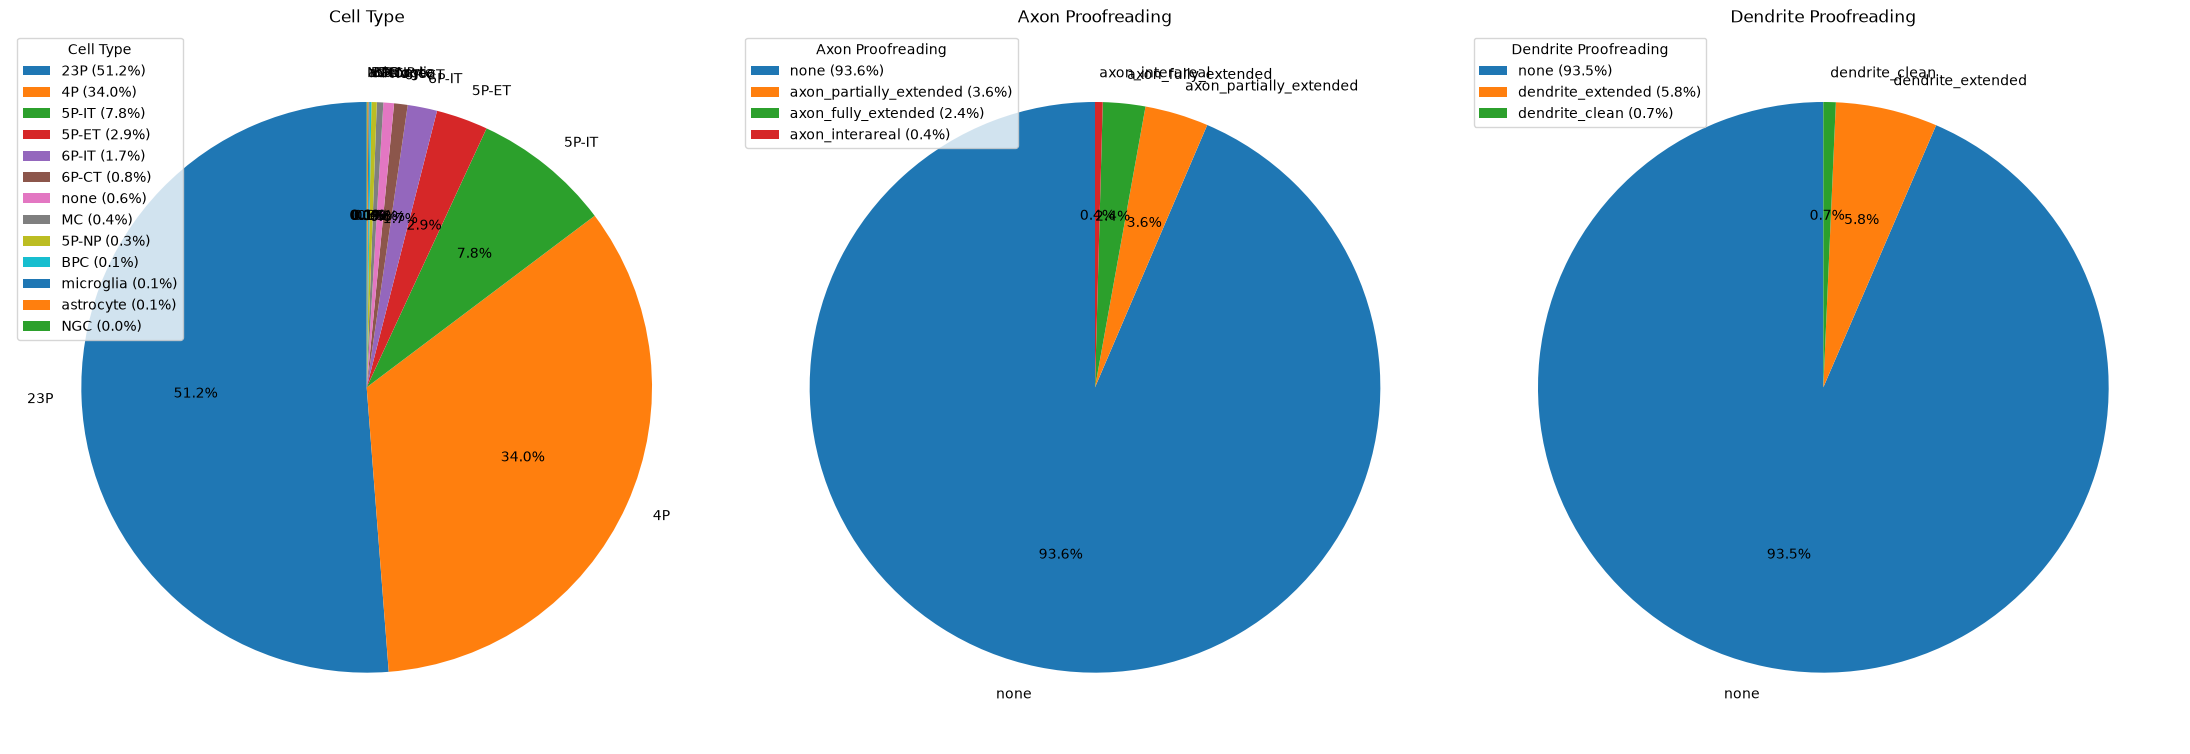

In [86]:
import matplotlib.pyplot as plt

cell_type_p = neurons_df["cell_type"].value_counts(normalize=True) * 100
axon_proof_p = neurons_df["axon_proof"].value_counts(normalize=True) * 100
dend_proof_p = neurons_df["dend_proof"].value_counts(normalize=True) * 100

fig, axes = plt.subplots(1, 3, figsize=(22, 8))

neurons_df["cell_type"].fillna("none").astype(str).value_counts().plot.pie(
  ax=axes[0],
  ylabel="",
  autopct="%1.1f%%",
  startangle=90,
)
axes[0].set_title("Cell Type")
handles, labels = axes[0].get_legend_handles_labels()
axes[0].legend(
  handles,
  [f"{label} ({cell_type_p.get(label, 0):.1f}%)" for label in labels],
  title="Cell Type",
)

neurons_df["axon_proof"].fillna("none").value_counts().plot.pie(
  ax=axes[1],
  ylabel="",
  autopct="%1.1f%%",
  startangle=90,
)
axes[1].set_title("Axon Proofreading")
handles, labels = axes[1].get_legend_handles_labels()
axes[1].legend(
  handles,
  [f"{label} ({axon_proof_p.get(label, 0):.1f}%)" for label in labels],
  title="Axon Proofreading",
)

neurons_df["dend_proof"].fillna("none").value_counts().plot.pie(
  ax=axes[2],
  ylabel="",
  autopct="%1.1f%%",
  startangle=90,
)
axes[2].set_title("Dendrite Proofreading")
handles, labels = axes[2].get_legend_handles_labels()
axes[2].legend(
  handles,
  [f"{label} ({dend_proof_p.get(label, 0):.1f}%)" for label in labels],
  title="Dendrite Proofreading",
)

plt.tight_layout()
plt.show()

# 3. Construct Synapse Lookup

We are going to build `synapses_df`, a general-purpose synapse information lookup. Here are the table headers:
| Key | Type | Description |
| - | - | - |
| `pre_post` | str | INDEX, structured like `<pre_id>_<post_id>` |
| `n` | int | the number of synapses |

In [87]:
import os
import math

BATCH_SIZE = 100

ids = neurons_df.index.to_list()

cache_dir = f"cache/synapses/n{neurons_df.shape[0]}_bs{BATCH_SIZE}"
os.makedirs(cache_dir, exist_ok=True)

n_batches = math.ceil(neurons_df.shape[0] / BATCH_SIZE)
for batch_i in range(n_batches):
  file = os.path.join(cache_dir, f"b{batch_i}.parquet")
  if os.path.exists(file):
    print(f"Fetching batch {batch_i}/{n_batches}: SKIPPED, exists")
    continue
  start = batch_i * BATCH_SIZE
  stop = min((batch_i + 1) * BATCH_SIZE, neurons_df.shape[0])
  print(f"Fetching batch {batch_i}/{n_batches}: [{start}, {stop})...")
  pre_ids = ids[start:stop]
  post_ids = ids
  batch_df = client.materialize.synapse_query(
    pre_ids=pre_ids,
    post_ids=post_ids,
    remove_autapses=True,
    desired_resolution=[1]*3,
    split_positions=True,
  )
  batch_df.to_parquet(file)
  print(f"Fetched batch {batch_i}")

batch_dfs = []
for batch_i in range(n_batches):
  batch_df = pd.read_parquet(os.path.join(cache_dir, f"b{batch_i}.parquet"))
  batch_dfs.append(batch_df)

raw_synapses_df = pd.concat(batch_dfs, axis=0)
print(raw_synapses_df.columns.to_list())
display(raw_synapses_df.head())

Fetching batch 0/30: SKIPPED, exists
Fetching batch 1/30: SKIPPED, exists
Fetching batch 2/30: SKIPPED, exists
Fetching batch 3/30: SKIPPED, exists
Fetching batch 4/30: SKIPPED, exists
Fetching batch 5/30: SKIPPED, exists
Fetching batch 6/30: SKIPPED, exists
Fetching batch 7/30: SKIPPED, exists
Fetching batch 8/30: SKIPPED, exists
Fetching batch 9/30: SKIPPED, exists
Fetching batch 10/30: SKIPPED, exists
Fetching batch 11/30: SKIPPED, exists
Fetching batch 12/30: SKIPPED, exists
Fetching batch 13/30: SKIPPED, exists
Fetching batch 14/30: SKIPPED, exists
Fetching batch 15/30: SKIPPED, exists
Fetching batch 16/30: SKIPPED, exists
Fetching batch 17/30: SKIPPED, exists
Fetching batch 18/30: SKIPPED, exists
Fetching batch 19/30: SKIPPED, exists
Fetching batch 20/30: SKIPPED, exists
Fetching batch 21/30: SKIPPED, exists
Fetching batch 22/30: SKIPPED, exists
Fetching batch 23/30: SKIPPED, exists
Fetching batch 24/30: SKIPPED, exists
Fetching batch 25/30: SKIPPED, exists
Fetching batch 26/30: 

,id,created,superceded_id,valid,pre_pt_position_x,pre_pt_position_y,pre_pt_position_z,post_pt_position_x,post_pt_position_y,post_pt_position_z,ctr_pt_position_x,ctr_pt_position_y,ctr_pt_position_z,size,pre_pt_supervoxel_id,pre_pt_root_id,post_pt_supervoxel_id,post_pt_root_id
1,93259878,2020-11-04 06:49:11.336675+00:00,<NA>,True,559464,626736,643280,559128,626984,642960,559448,627104,643400,5860.0,84033131224755619,864691135349171415,83962762480575202,864691136451805439
2,110308336,2020-11-04 06:49:11.886757+00:00,<NA>,True,599408,736312,891320,599680,736232,891440,599712,736500,891200,8088.0,85373849021274786,864691135939008565,85373849021278797,864691135867139548
3,60481364,2020-11-04 06:48:58.480065+00:00,<NA>,True,474824,666848,731120,474776,666960,731400,474848,666896,731400,2712.0,81079018627460962,864691135565618007,81079018627469522,864691135502833077
4,117865429,2020-11-04 07:20:39.680234+00:00,<NA>,True,611256,459504,762280,611592,459696,762320,611384,459680,762280,7184.0,85786715234662282,864691135477511592,85786783954151155,864691135889475721
5,95739978,2020-11-04 07:36:44.085358+00:00,<NA>,True,568552,597584,754240,568304,597792,754200,568328,597744,754160,352.0,84313644464572847,864691135477511592,84313644464563171,864691135369713913


In [88]:
synapses_df = (
  raw_synapses_df
  .groupby(["pre_pt_root_id", "post_pt_root_id"])
  .size()
  .rename("n")
  .to_frame()
)
synapses_df.index.names = ["pre_id", "post_id"]

print(synapses_df.columns.to_list())
display(synapses_df.head())

['n']


n
pre_id             post_id              
864691134885069562 864691135464232861  1
                   864691135566992471  1
                   864691135581617517  1
                   864691135856762158  1
864691134885544698 864691135014265334  1

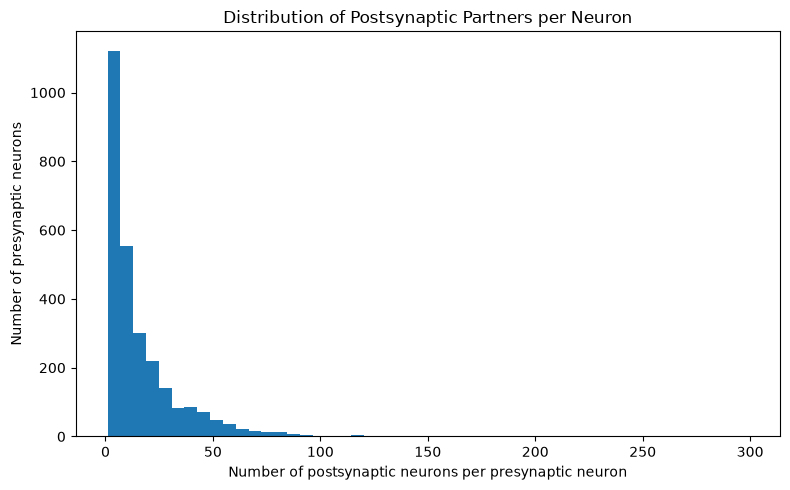

In [89]:
import matplotlib.pyplot as plt

posts_per_pre = (
  synapses_df
  .reset_index()
  .groupby("pre_id")["post_id"]
  .nunique()
)

plt.figure(figsize=(8, 5))
plt.hist(posts_per_pre, bins=50)

plt.xlabel("Number of postsynaptic neurons per presynaptic neuron")
plt.ylabel("Number of presynaptic neurons")
plt.title("Distribution of Postsynaptic Partners per Neuron")

plt.tight_layout()
plt.show()